# Mean Turbulent Pipe Flow with Algebraic Mixing-Length Closures
### Finite-volume solution of the axisymmetric RANS momentum equation: Prandtl vs. van Driest models


In [1]:
import os, shutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.optimize import brentq

FIG = "figures"
os.makedirs(FIG, exist_ok=True)

def show(fig, name, dpi=150):
    """Save a figure to ./figures and display it inline."""
    path = f"{FIG}/{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=path))

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print("environment ready")

environment ready


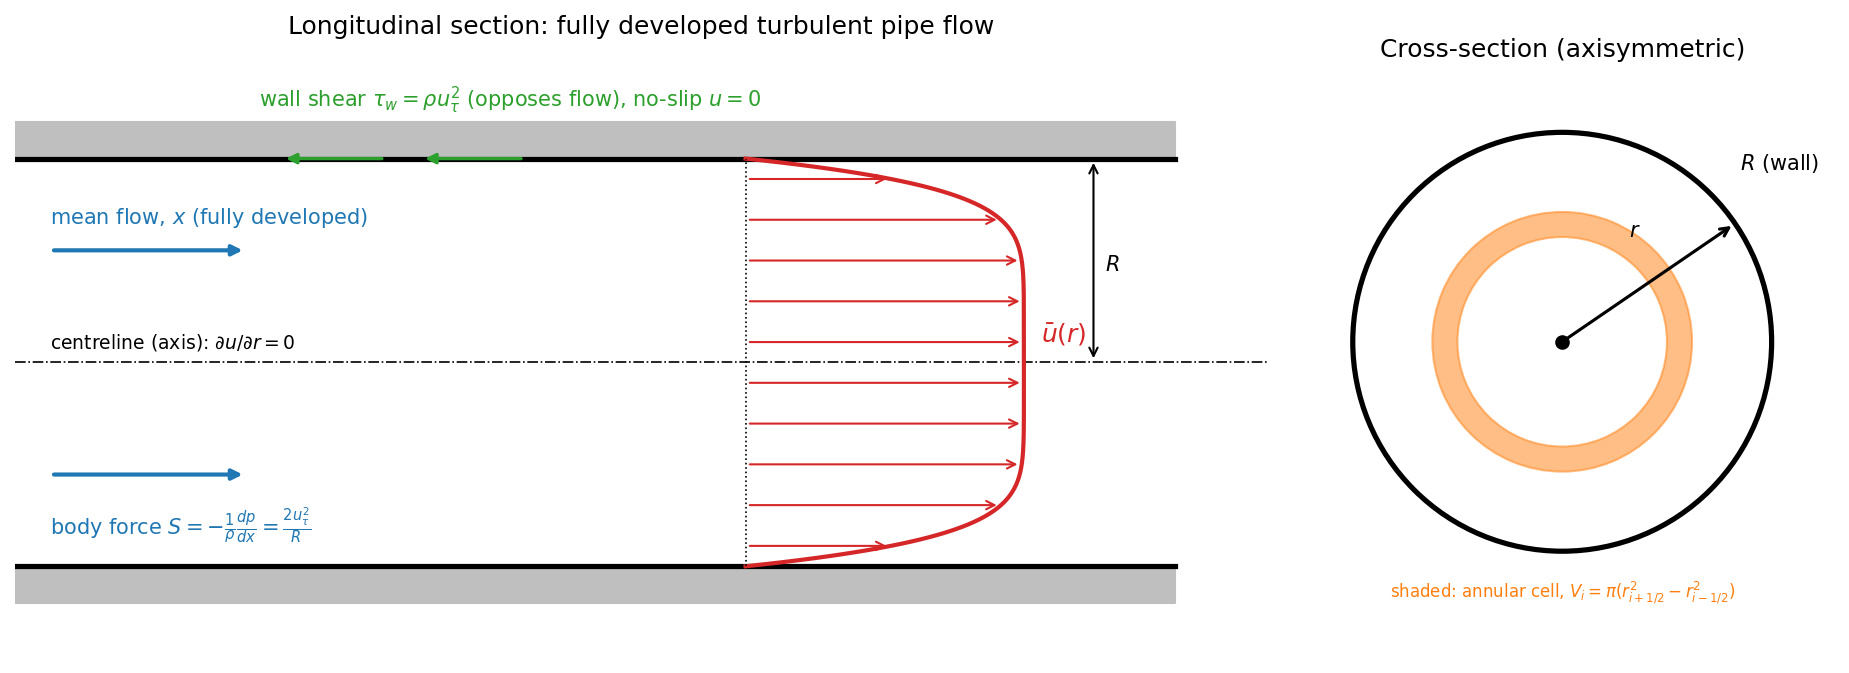

In [2]:
from matplotlib.patches import Circle, Wedge, FancyArrowPatch

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
L = 10
a1.fill_between([0, L], 1, 1.18, color="0.75"); a1.fill_between([0, L], -1.18, -1, color="0.75")
a1.plot([0, L], [1, 1], "k", lw=2.5); a1.plot([0, L], [-1, -1], "k", lw=2.5)
a1.axhline(0, color="k", ls="-.", lw=0.8)
x0 = 6.3
rr_ = np.linspace(-1, 1, 200)
a1.plot(x0 + 2.4 * (1 - np.abs(rr_) ** 7), rr_, color="C3", lw=2)
a1.plot([x0, x0], [-1, 1], "k:", lw=0.8)
for q in np.linspace(-0.9, 0.9, 10):
    a1.annotate("", xy=(x0 + 2.4 * (1 - abs(q) ** 7), q), xytext=(x0, q),
                arrowprops=dict(arrowstyle="->", color="C3", lw=1))
a1.text(x0 + 2.55, 0.1, r"$\bar u(r)$", color="C3", fontsize=12)
a1.annotate("", xy=(2.0, 0.55), xytext=(0.3, 0.55), arrowprops=dict(arrowstyle="-|>", lw=2, color="C0"))
a1.text(0.3, 0.68, "mean flow, $x$ (fully developed)", color="C0")
a1.annotate("", xy=(2.0, -0.55), xytext=(0.3, -0.55), arrowprops=dict(arrowstyle="-|>", lw=2, color="C0"))
a1.text(0.3, -0.85, r"body force $S=-\frac{1}{\rho}\frac{dp}{dx}=\frac{2u_\tau^2}{R}$", color="C0")
for xx in (3.2, 4.4):
    a1.annotate("", xy=(xx - 0.9, 1.0), xytext=(xx, 1.0), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="C2"))
a1.text(2.1, 1.25, r"wall shear $\tau_w=\rho u_\tau^2$ (opposes flow), no-slip $u=0$", color="C2")
a1.annotate("", xy=(9.3, 0.0), xytext=(9.3, 1.0), arrowprops=dict(arrowstyle="<->", lw=1))
a1.text(9.4, 0.45, "$R$")
a1.text(0.3, 0.07, "centreline (axis): $\\partial u/\\partial r=0$", fontsize=9)
a1.set(xlim=(0, L + 0.8), ylim=(-1.45, 1.55), title="Longitudinal section: fully developed turbulent pipe flow")
a1.set_aspect("auto"); a1.axis("off"); a1.set_title("Longitudinal section: fully developed turbulent pipe flow")

a2.add_patch(Circle((0, 0), 1, fill=False, lw=2.5))
a2.add_patch(Circle((0, 0), 1.12, fill=False, lw=0, ec="none"))
a2.add_patch(Wedge((0, 0), 0.62, 0, 360, width=0.12, color="C1", alpha=0.5))
a2.annotate("", xy=(np.cos(0.6), np.sin(0.6)), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=1.5))
a2.text(0.32, 0.5, "$r$"); a2.text(0.85, 0.82, "$R$ (wall)")
a2.text(0, -1.22, "shaded: annular cell, $V_i=\\pi(r_{i+1/2}^2-r_{i-1/2}^2)$", fontsize=8, color="C1", ha="center")
a2.plot(0, 0, "ko")
a2.set(xlim=(-1.3, 1.3), ylim=(-1.4, 1.3), aspect="equal", title="Cross-section (axisymmetric)")
a2.axis("off"); a2.set_title("Cross-section (axisymmetric)")
fig.tight_layout()
show(fig, "fig01_problem_schematic")

**Figure 1.** Physical problem, boundary conditions and the annular control volume. The pressure gradient (equivalently $u_\tau$) drives the flow; the wall shear opposes it.

## 3. Assumptions and limitations

1. Incompressible, Newtonian fluid with constant properties.
2. Statistically steady, fully developed, axisymmetric mean flow; no swirl, no radial mean velocity.
3. Smooth wall (no roughness).
4. Algebraic (zero-equation) closure: $\nu_t$ is a local function of the mean shear and wall distance; no transport of turbulence quantities, no wake or history effects.
5. $u_\tau$ is **prescribed**; $U_b$, $Re_D$ and $f_D$ are results.
6. Uniform radial grid; first cell centre at $y^+ \approx 1.25$ so the viscous sub-layer is resolved without wall functions.
7. The wall-face effective viscosity is set to the molecular value ($\ell_m=0$ at $y=0$), and the wall shear is evaluated with a one-sided difference over $h/2$.

**Known limitations of the physics:** the algebraic models contain no outer-layer wake correction (so they are expected to be least accurate near the axis), and the Prandtl model has no viscous damping.

In [4]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

R = 0.025
NU = 1.5e-5
RHO = 1.2
U_TAU = 0.18
KAPPA = 0.41
A_PLUS = 26.0
N = 120
MAX_ITER = 1000
TOL = 1.0e-10

h = R / N
r = (np.arange(N) + 0.5) * h
rf = np.arange(N + 1) * h
source = 2.0 * U_TAU**2 / R
volume = np.pi * (rf[1:]**2 - rf[:-1]**2)
area = 2.0 * np.pi * rf

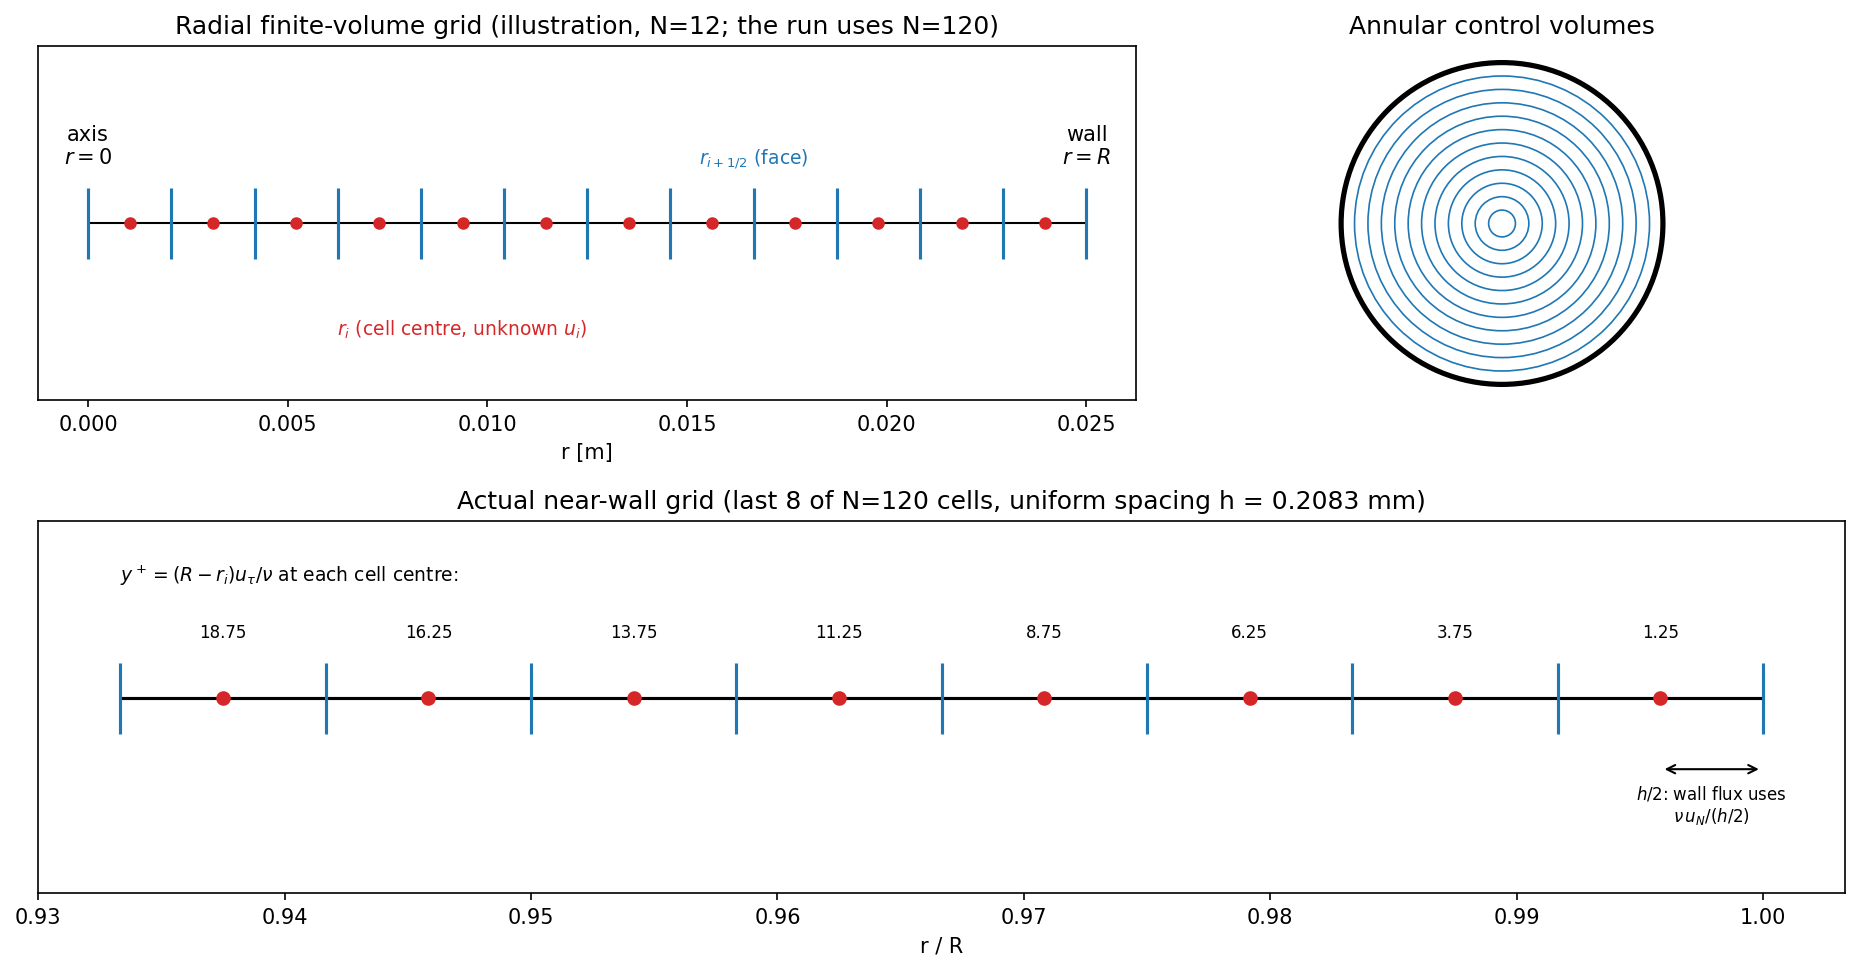

In [5]:
fig = plt.figure(figsize=(12.5, 6.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], width_ratios=[1.6, 1])
a = fig.add_subplot(gs[0, 0]); b = fig.add_subplot(gs[0, 1]); c = fig.add_subplot(gs[1, :])

# (a) illustrative coarse grid, n=12
n_i = 12; h_i = R / n_i
rf_i = np.arange(n_i + 1) * h_i; rc_i = (np.arange(n_i) + .5) * h_i
a.hlines(0, 0, R, color="k", lw=1)
for x in rf_i: a.vlines(x, -0.12, 0.12, color="C0")
a.plot(rc_i, np.zeros(n_i), "o", color="C3", ms=5)
a.text(0, 0.2, "axis\n$r=0$", ha="center"); a.text(R, 0.2, "wall\n$r=R$", ha="center")
a.text(rc_i[4], -0.38, "$r_i$ (cell centre, unknown $u_i$)", color="C3", ha="center", fontsize=9)
a.text(rf_i[8], 0.2, "$r_{i+1/2}$ (face)", color="C0", ha="center", fontsize=9)
a.set(ylim=(-0.6, 0.6), title=f"Radial finite-volume grid (illustration, N={n_i}; the run uses N={N})")
a.set_yticks([]); a.grid(False); a.set_xlabel("r [m]")

# (b) concentric rings
for k in range(n_i):
    b.add_patch(plt.Circle((0, 0), rf_i[k + 1] / R, fill=False, lw=0.8, color="C0"))
b.add_patch(plt.Circle((0, 0), 1, fill=False, lw=2.5, color="k"))
b.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal", title="Annular control volumes"); b.axis("off")

# (c) actual near-wall grid
k0 = N - 8
c.hlines(0, rf[k0] / R, 1, color="k")
for x in rf[k0:]: c.vlines(x / R, -0.1, 0.1, color="C0")
c.plot(r[k0:] / R, np.zeros(N - k0), "o", color="C3")
for i in range(k0, N):
    c.text(r[i] / R, 0.17, f"{(R - r[i]) * U_TAU / NU:.2f}", ha="center", fontsize=8, rotation=0)
c.text(rf[k0] / R, 0.33, "$y^+=(R-r_i)u_\\tau/\\nu$ at each cell centre:", fontsize=9, ha="left")
c.annotate("", xy=(1, -0.2), xytext=(r[-1] / R, -0.2), arrowprops=dict(arrowstyle="<->"))
c.text((1 + r[-1] / R) / 2, -0.35, "$h/2$: wall flux uses\n$\\nu\\,u_N/(h/2)$", ha="center", fontsize=8)
c.set(ylim=(-0.55, 0.5), xlabel="r / R", title=f"Actual near-wall grid (last 8 of N={N} cells, uniform spacing h = {h*1e3:.4f} mm)")
c.set_yticks([]); c.grid(False)
fig.tight_layout()
show(fig, "fig02_computational_grid")

In [6]:
def solve_linear(eff):
    conductance = area[1:-1] * eff[1:-1] / h
    diagonal = np.zeros(N)
    diagonal[:-1] += conductance
    diagonal[1:] += conductance
    wall_conductance = area[-1] * NU / (0.5 * h)
    diagonal[-1] += wall_conductance
    matrix = diags([ -conductance, diagonal, -conductance], [-1, 0, 1], format="csr")
    return spsolve(matrix, source * volume)

In [7]:
def model(name):
    velocity = solve_linear(np.full(N + 1, NU))
    diff = np.inf
    for count in range(1, MAX_ITER + 1):
        slope = np.zeros(N + 1)
        slope[1:-1] = (velocity[1:] - velocity[:-1]) / h
        slope[-1] = -velocity[-1] / (0.5 * h)
        y = R - rf
        mixing = KAPPA * y
        if name == "van Driest":
            mixing *= 1.0 - np.exp(-y * U_TAU / (A_PLUS * NU))
        eff = NU + mixing**2 * np.abs(slope)
        eff[-1] = NU
        new = solve_linear(eff)
        diff = float(np.max(np.abs(new - velocity)))
        velocity = 0.25 * new + 0.75 * velocity
        if diff < TOL:
            velocity = new
            break
    if count == MAX_ITER:
        raise RuntimeError(name + " Picard solver did not converge")
    slope = np.zeros(N + 1)
    slope[1:-1] = (velocity[1:] - velocity[:-1]) / h
    slope[-1] = -velocity[-1] / (0.5 * h)
    mixing = KAPPA * (R - rf)
    if name == "van Driest":
        mixing *= 1.0 - np.exp(-(R - rf) * U_TAU / (A_PLUS * NU))
    eff = NU + mixing**2 * np.abs(slope)
    eff[-1] = NU
    residual = np.max(np.abs(solve_linear(eff) - velocity))
    bulk = float(np.sum(volume * velocity) / (np.pi * R**2))
    reynolds = 2.0 * R * bulk / NU
    darcy_f = 8 * (U_TAU / bulk)**2
    return velocity, bulk, reynolds, darcy_f, count, residual

In [8]:
laminar = solve_linear(np.full(N + 1, NU))
laminar_bulk = np.sum(volume * laminar) / (np.pi * R**2)
exact_laminar = source * (R**2 - r**2) / (4 * NU)
laminar_error = np.max(np.abs(laminar - exact_laminar))
models = {name: model(name) for name in ("Prandtl", "van Driest")}

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(laminar / laminar_bulk, r / R, color="gray", ls="--", label="Laminar reference")
for name, (velocity, bulk, reynolds, f, count, residual) in models.items():
    axes[0].plot(velocity / bulk, r / R, label=name)
axes[0].set(xlabel="u / Ubulk", ylabel="r / R", title="Mean velocity profiles")
axes[0].legend(fontsize=8)
for name, (_, bulk, reynolds, f, _, _) in models.items():
    axes[1].plot(reynolds, f, "o", ms=8, label=name)
re_grid = np.linspace(4000, 14000, 250)
axes[1].plot(re_grid, 0.3164 * re_grid**(-0.25), label="Blasius (smooth-pipe correlation)")
axes[1].set(xlabel="Re based on bulk speed", ylabel="Darcy friction factor", title="Friction-factor comparison", xlim=(4000, 14000))
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("experiment_10_pipe_output.png", dpi=160)
plt.close(fig)
print(f"N={N}, radius={R}, nu={NU}, u_tau={U_TAU}, Re_tau={U_TAU*R/NU:.1f}")
print(f"Laminar_FVM_max_error={laminar_error:.3e}, laminar_Ubulk={laminar_bulk:.6f}")
for name, (_, bulk, reynolds, f, count, residual) in models.items():
    print(f"{name}: Ubulk={bulk:.6f}, Re_D={reynolds:.2f}, Darcy_f={f:.6f}, Blasius_f={0.3164*reynolds**(-0.25):.6f}, Picard_iterations={count}, fixed_point_error={residual:.3e}")
print("figure=experiment_10_pipe_output.png")

N=120, radius=0.025, nu=1.5e-05, u_tau=0.18, Re_tau=300.0
Laminar_FVM_max_error=4.687e-04, laminar_Ubulk=13.500937
Prandtl: Ubulk=1.572805, Re_D=5242.68, Darcy_f=0.104782, Blasius_f=0.037183, Picard_iterations=53, fixed_point_error=2.656e-11
van Driest: Ubulk=2.616125, Re_D=8720.42, Darcy_f=0.037872, Blasius_f=0.032742, Picard_iterations=65, fixed_point_error=5.938e-12
figure=experiment_10_pipe_output.png


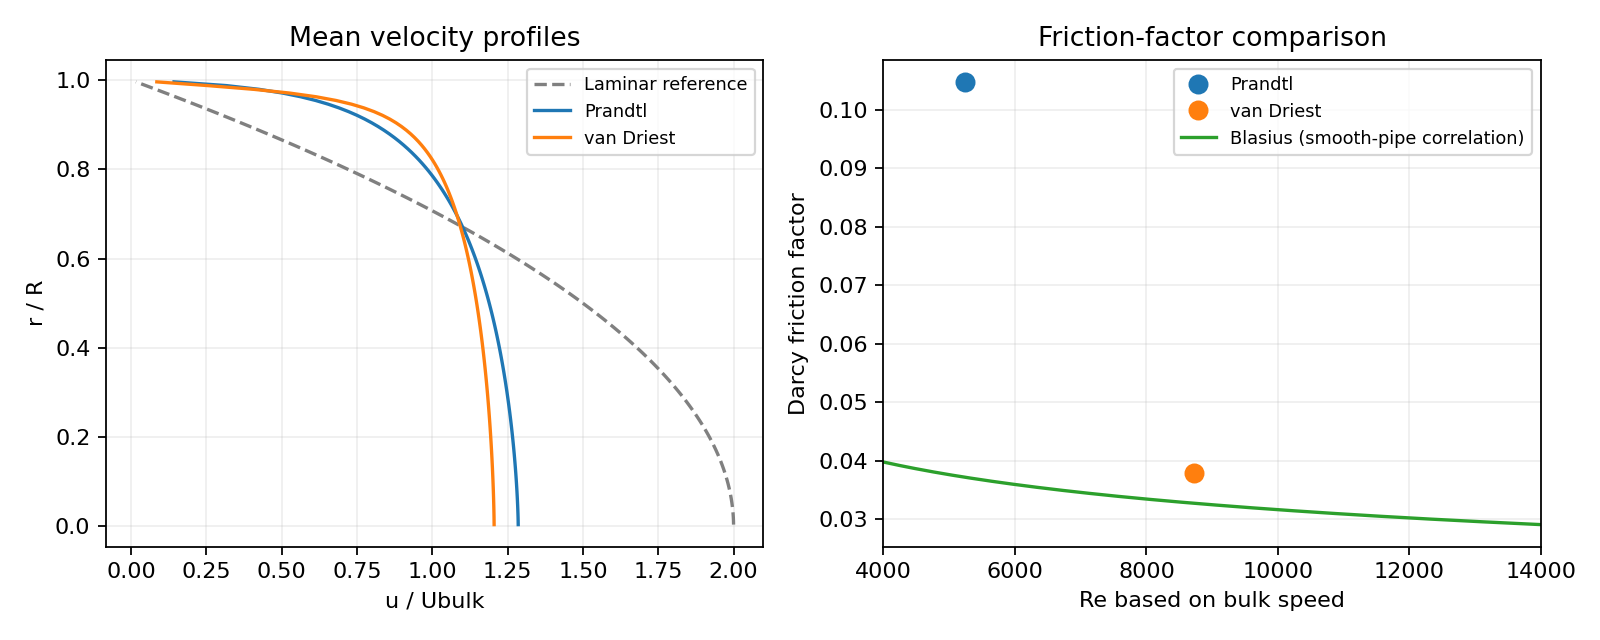

In [10]:
shutil.copy("experiment_10_pipe_output.png", f"{FIG}/fig04_original_output.png")
display(Image(filename="experiment_10_pipe_output.png"))

In [11]:
params = pd.DataFrame([
    ("Pipe radius R", "m", R),
    ("Kinematic viscosity nu", "m^2/s", NU),
    ("Density rho", "kg/m^3", RHO),
    ("Friction velocity u_tau", "m/s", U_TAU),
    ("von Karman constant kappa", "-", KAPPA),
    ("van Driest constant A+", "-", A_PLUS),
    ("Number of radial cells N", "-", N),
    ("Cell size h = R/N", "m", h),
    ("Body-force source S = 2 u_tau^2 / R", "m/s^2", source),
    ("Wall shear stress tau_w = rho u_tau^2", "Pa", RHO * U_TAU**2),
    ("Pressure gradient -dp/dx = 2 tau_w / R", "Pa/m", 2 * RHO * U_TAU**2 / R),
    ("Friction Reynolds number Re_tau = u_tau R / nu", "-", U_TAU * R / NU),
    ("First-cell wall distance y1+ = (h/2) u_tau / nu", "-", 0.5 * h * U_TAU / NU),
    ("Picard tolerance", "m/s", TOL),
    ("Under-relaxation factor", "-", 0.25),
], columns=["Quantity", "Unit", "Value"])
params

,Quantity,Unit,Value
0,Pipe radius R,m,0.025
1,Kinematic viscosity nu,m^2/s,1.5e-05
2,Density rho,kg/m^3,1.2
3,Friction velocity u_tau,m/s,0.18
4,von Karman constant kappa,-,0.41
5,van Driest constant A+,-,26
6,Number of radial cells N,-,120
7,Cell size h = R/N,m,0.000208333
8,Body-force source S = 2 u_tau^2 / R,m/s^2,2.592
9,Wall shear stress tau_w = rho u_tau^2,Pa,0.03888


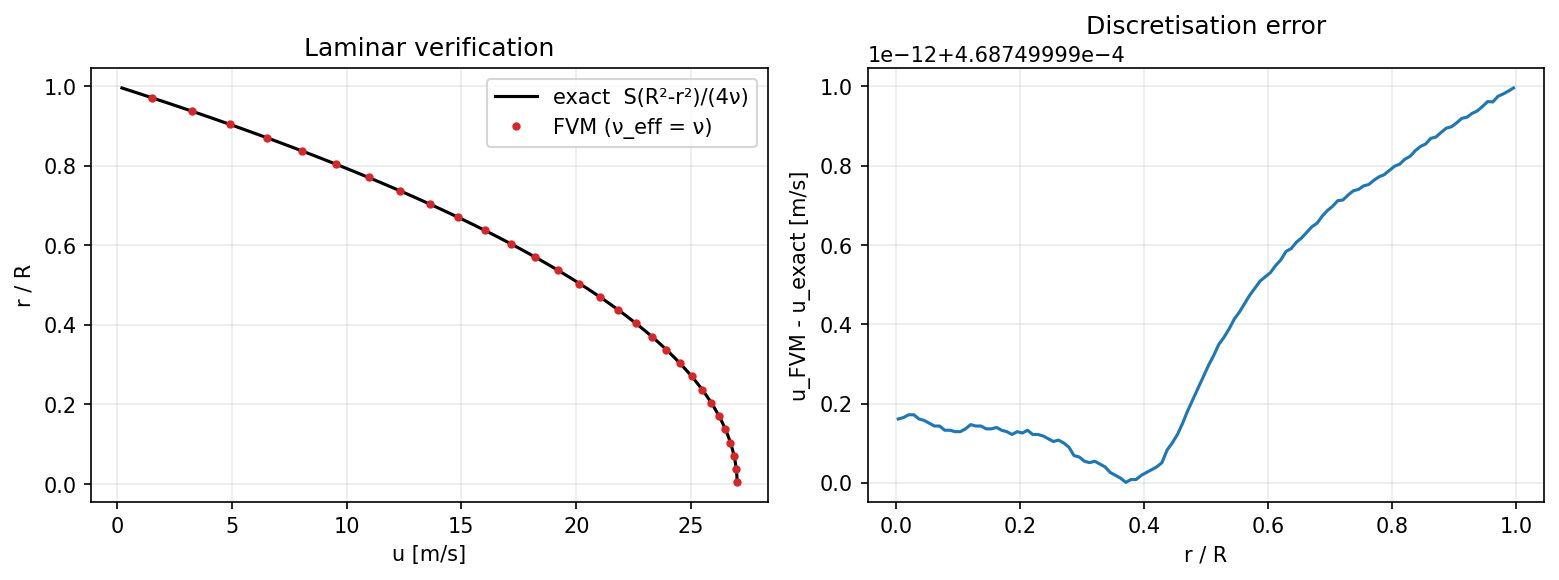

max |error| = 4.6875e-04 m/s  (1.7361e-03 % of centreline value)


In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 4))
a.plot(exact_laminar, r / R, "k-", label="exact  S(R²-r²)/(4ν)")
a.plot(laminar, r / R, "C3o", ms=3, markevery=4, label="FVM (ν_eff = ν)")
a.set(xlabel="u [m/s]", ylabel="r / R", title="Laminar verification"); a.legend()
b.plot(r / R, laminar - exact_laminar, "C0")
b.set(xlabel="r / R", ylabel="u_FVM - u_exact [m/s]", title="Discretisation error")
fig.tight_layout(); show(fig, "fig05_laminar_verification")
print(f"max |error| = {laminar_error:.4e} m/s  ({laminar_error/exact_laminar.max()*100:.4e} % of centreline value)")

In [13]:
def run_model(name, n=N, u_tau=U_TAU, nu=NU, radius=R, kappa=KAPPA, a_plus=A_PLUS,
              relax=0.25, tol=TOL, max_iter=MAX_ITER):
    """Parametrised re-implementation of the original model() (same algorithm,
    same discretisation) that additionally records the Picard history and the
    final eddy-viscosity fields. Used for the grid study and the Re scan."""
    h_ = radius / n
    r_ = (np.arange(n) + 0.5) * h_
    rf_ = np.arange(n + 1) * h_
    src = 2.0 * u_tau**2 / radius
    vol = np.pi * (rf_[1:]**2 - rf_[:-1]**2)
    ar = 2.0 * np.pi * rf_

    def lin(eff):
        cond = ar[1:-1] * eff[1:-1] / h_
        dg = np.zeros(n)
        dg[:-1] += cond
        dg[1:] += cond
        dg[-1] += ar[-1] * nu / (0.5 * h_)
        return spsolve(diags([-cond, dg, -cond], [-1, 0, 1], format="csr"), src * vol)

    def closure(vel):
        slope = np.zeros(n + 1)
        slope[1:-1] = (vel[1:] - vel[:-1]) / h_
        slope[-1] = -vel[-1] / (0.5 * h_)
        y_ = radius - rf_
        lm = kappa * y_
        if name == "van Driest":
            lm = lm * (1.0 - np.exp(-y_ * u_tau / (a_plus * nu)))
        eff = nu + lm**2 * np.abs(slope)
        eff[-1] = nu
        return eff, slope, lm

    vel = lin(np.full(n + 1, nu))
    hist, converged = [], False
    for it in range(1, max_iter + 1):
        eff, _, _ = closure(vel)
        new = lin(eff)
        d = float(np.max(np.abs(new - vel)))
        hist.append(d)
        vel = relax * new + (1.0 - relax) * vel
        if d < tol:
            vel, converged = new, True
            break
    if not converged:
        raise RuntimeError(f"{name} Picard solver did not converge")
    eff, slope, lm = closure(vel)
    resid = float(np.max(np.abs(lin(eff) - vel)))
    bulk = float(np.sum(vol * vel) / (np.pi * radius**2))
    Re = 2.0 * radius * bulk / nu
    f = 8.0 * (u_tau / bulk) ** 2
    return dict(name=name, n=n, h=h_, r=r_, rf=rf_, u=vel, eff=eff, slope=slope, lm=lm,
                bulk=bulk, Re=Re, f=f, iters=it, resid=resid, hist=np.array(hist),
                u_tau=u_tau, vol=vol)

def f_blasius(Re):
    return 0.3164 * Re ** (-0.25)

def f_prandtl_karman(Re):
    """Smooth-pipe Prandtl-Karman law  1/sqrt(f) = 2 log10(Re sqrt(f)) - 0.8."""
    g = lambda f: 1.0 / np.sqrt(f) - (2.0 * np.log10(Re * np.sqrt(f)) - 0.8)
    return brentq(g, 1e-4, 1.0)

# --- Verification: the parametrised solver must reproduce the original script ---
chk = {}
for nm in ("Prandtl", "van Driest"):
    rr = run_model(nm)
    chk[nm] = dict(max_abs_diff_u=float(np.max(np.abs(rr["u"] - models[nm][0]))),
                   diff_f=abs(rr["f"] - models[nm][3]), iters_same=rr["iters"] == models[nm][4])
pd.DataFrame(chk).T

,max_abs_diff_u,diff_f,iters_same
Prandtl,0,0,True
van Driest,0,0,True


In [14]:
def summarise(res):
    u, rr_, y_ = res["u"], res["r"], res["rf"]
    ut = res["u_tau"]; Re = res["Re"]
    yp = (R - rr_) * ut / NU
    up = u / ut
    ref = 100.0
    uplus100 = float(np.interp(ref, yp[::-1], up[::-1]))
    nut = (res["eff"] - NU) / NU
    return {
        "U_bulk [m/s]": res["bulk"], "U_centreline [m/s]": float(u[0]),
        "U_cl / U_bulk": float(u[0] / res["bulk"]), "U_bulk+ = U_bulk/u_tau": res["bulk"] / ut,
        "Re_D": Re, "Darcy f (FVM)": res["f"], "f Blasius": f_blasius(Re),
        "f Prandtl-Karman": f_prandtl_karman(Re),
        "dev. from Blasius [%]": 100 * (res["f"] / f_blasius(Re) - 1),
        "dev. from Prandtl-Karman [%]": 100 * (res["f"] / f_prandtl_karman(Re) - 1),
        "max nu_t/nu": float(nut[1:-1].max()),
        "r/R where nu_t/nu is max": float(res["rf"][1:-1][np.argmax(nut[1:-1])] / R),
        "nu_t/nu at r/R = 0.5": float(np.interp(0.5, res["rf"] / R, nut)),
        "u+ at y+=100": uplus100,
        "implied log-law offset B": uplus100 - np.log(ref) / KAPPA,
        "U_b+ log-law estimate (kappa, B=5)": np.log(ut * R / NU) / KAPPA + 5.0 - 1.5 / KAPPA,
        "f from log-law estimate": 8.0 / (np.log(ut * R / NU) / KAPPA + 5.0 - 1.5 / KAPPA) ** 2,
        "Picard iterations": res["iters"], "fixed-point residual [m/s]": res["resid"],
    }

base = {nm: run_model(nm) for nm in ("Prandtl", "van Driest")}
summary = pd.DataFrame({nm: summarise(base[nm]) for nm in base})
summary

,Prandtl,van Driest
U_bulk [m/s],1.5728,2.61613
U_centreline [m/s],2.02139,3.15312
U_cl / U_bulk,1.28521,1.20526
U_bulk+ = U_bulk/u_tau,8.7378,14.534
Re_D,5242.68,8720.42
Darcy f (FVM),0.104782,0.037872
f Blasius,0.0371833,0.0327418
f Prandtl-Karman,0.0368959,0.0320391
dev. from Blasius [%],181.798,15.6687
dev. from Prandtl-Karman [%],183.993,18.2054


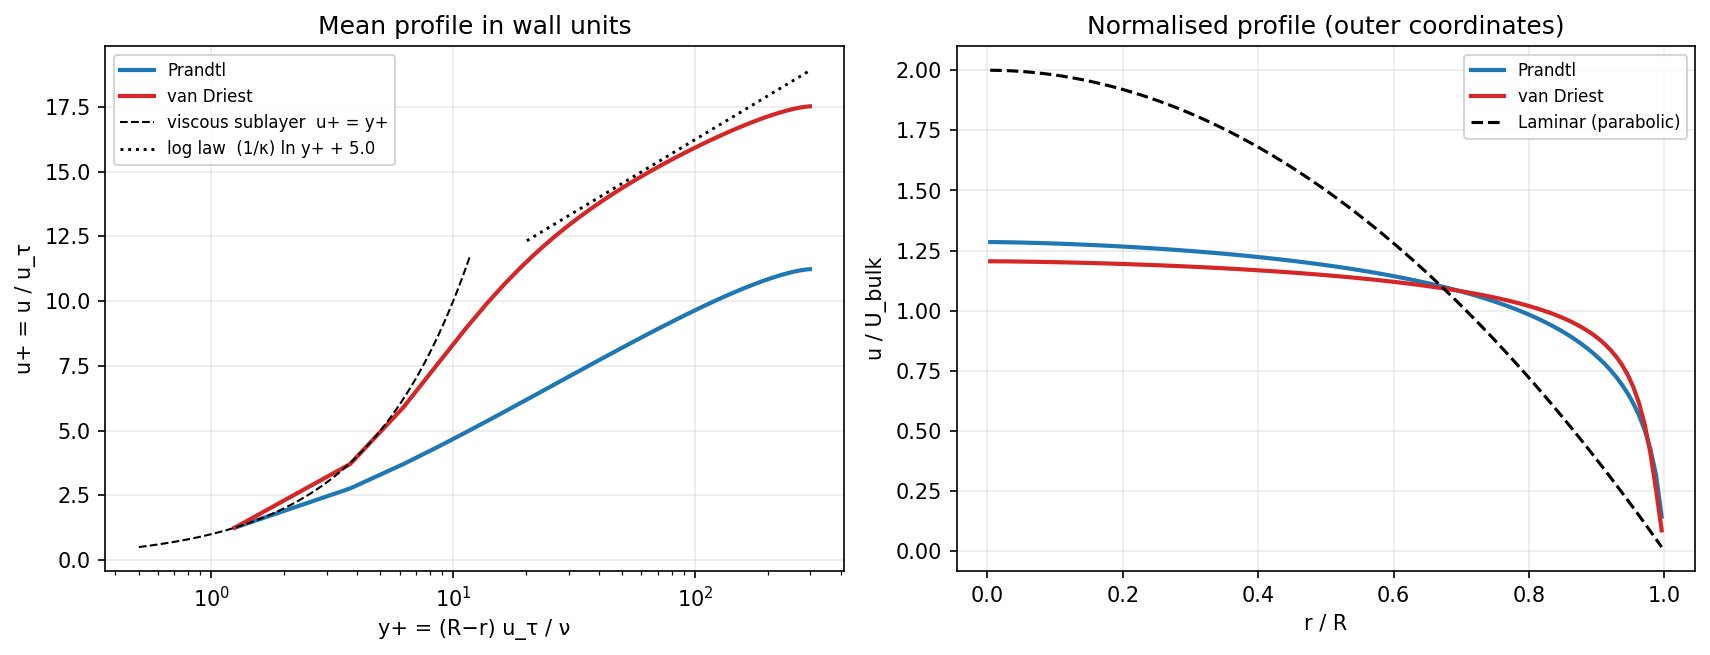

In [15]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.5))
for nm, col in zip(base, ("C0", "C3")):
    res = base[nm]
    yp = (R - res["r"]) * U_TAU / NU
    a.semilogx(yp, res["u"] / U_TAU, color=col, lw=2, label=nm)
yy = np.logspace(-0.3, np.log10(Re_tau := U_TAU * R / NU), 200)
a.semilogx(yy[yy < 12], yy[yy < 12], "k--", lw=1, label="viscous sublayer  u+ = y+")
a.semilogx(yy[yy > 20], np.log(yy[yy > 20]) / KAPPA + 5.0, "k:", lw=1.4, label="log law  (1/κ) ln y+ + 5.0")
a.set(xlabel="y+ = (R−r) u_τ / ν", ylabel="u+ = u / u_τ", title="Mean profile in wall units"); a.legend(fontsize=8)
for nm, col in zip(base, ("C0", "C3")):
    res = base[nm]
    b.plot(res["r"] / R, res["u"] / res["bulk"], color=col, lw=2, label=nm)
b.plot(r / R, laminar / laminar_bulk, "k--", label="Laminar (parabolic)")
b.set(xlabel="r / R", ylabel="u / U_bulk", title="Normalised profile (outer coordinates)"); b.legend(fontsize=8)
fig.tight_layout(); show(fig, "fig06_wall_units")

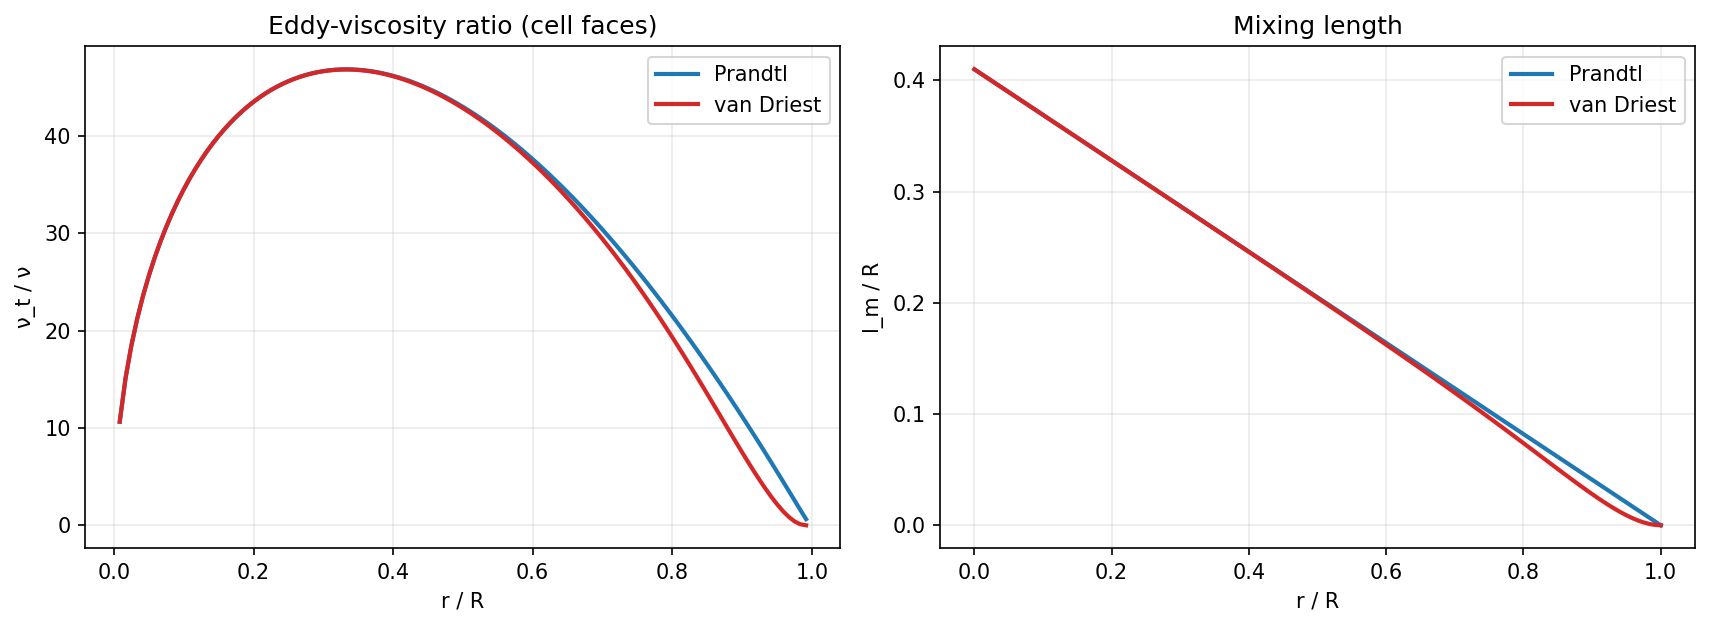

In [16]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.3))
for nm, col in zip(base, ("C0", "C3")):
    res = base[nm]
    a.plot(res["rf"][1:-1] / R, (res["eff"][1:-1] - NU) / NU, color=col, lw=2, label=nm)
    b.plot(res["rf"] / R, res["lm"] / R, color=col, lw=2, label=nm)
a.set(xlabel="r / R", ylabel="ν_t / ν", title="Eddy-viscosity ratio (cell faces)"); a.legend()
b.set(xlabel="r / R", ylabel="l_m / R", title="Mixing length"); b.legend()
fig.tight_layout(); show(fig, "fig07_eddy_viscosity")

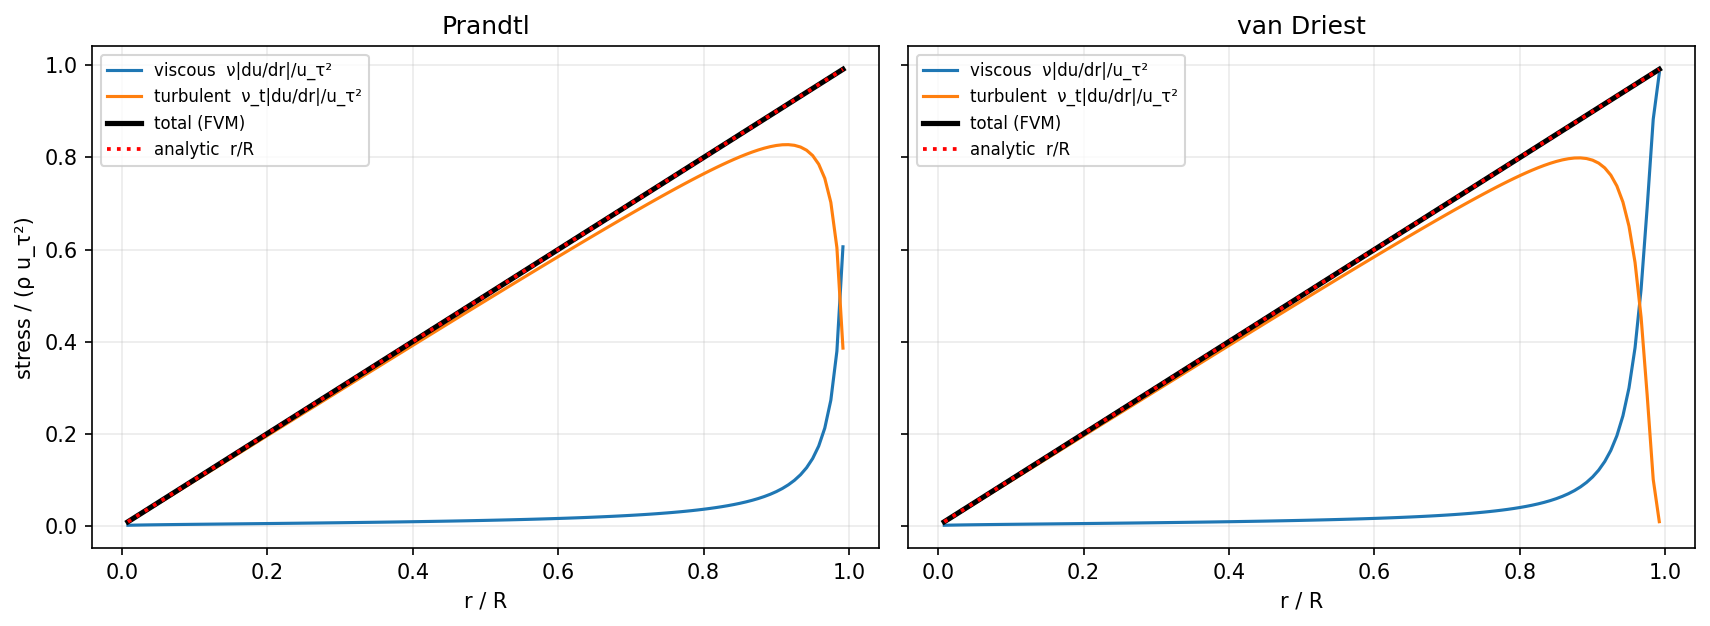

,max |total stress − r/R| (interior faces)
Prandtl,8.73374e-11
van Driest,1.33071e-11


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True)
stress_check = {}
for ax, nm in zip(axs, base):
    res = base[nm]
    rfi = res["rf"][1:-1]
    shear = np.abs(res["slope"][1:-1])
    visc = NU * shear / U_TAU**2
    turb = (res["eff"][1:-1] - NU) * shear / U_TAU**2
    ax.plot(rfi / R, visc, label="viscous  ν|du/dr|/u_τ²")
    ax.plot(rfi / R, turb, label="turbulent  ν_t|du/dr|/u_τ²")
    ax.plot(rfi / R, visc + turb, "k", lw=2.5, label="total (FVM)")
    ax.plot(rfi / R, rfi / R, "r:", lw=1.8, label="analytic  r/R")
    ax.set(xlabel="r / R", title=nm); ax.legend(fontsize=8)
    stress_check[nm] = float(np.max(np.abs(visc + turb - rfi / R)))
axs[0].set_ylabel("stress / (ρ u_τ²)")
fig.tight_layout(); show(fig, "fig08_stress_budget")
pd.Series(stress_check, name="max |total stress − r/R|  (interior faces)").to_frame()

**Figure 8.** Decomposition of the total shear stress into viscous and turbulent parts.

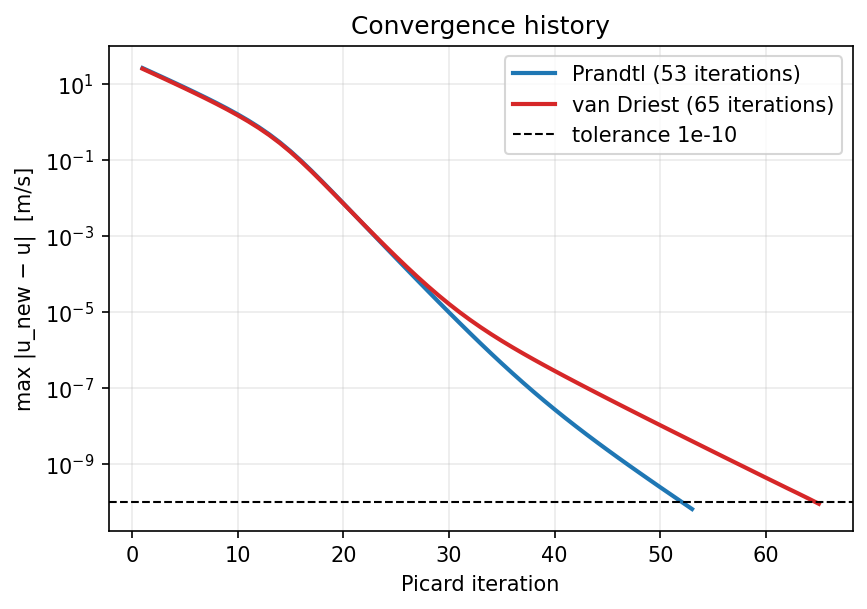

,mean contraction factor per iteration (last 10 it.)
Prandtl,0.635691
van Driest,0.729064


In [18]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for nm, col in zip(base, ("C0", "C3")):
    ax.semilogy(np.arange(1, base[nm]["iters"] + 1), base[nm]["hist"], color=col, lw=2, label=f"{nm} ({base[nm]['iters']} iterations)")
ax.axhline(TOL, color="k", ls="--", lw=1, label="tolerance 1e-10")
ax.set(xlabel="Picard iteration", ylabel="max |u_new − u|  [m/s]", title="Convergence history"); ax.legend()
show(fig, "fig09_convergence")
rates = {nm: float((base[nm]["hist"][-1] / base[nm]["hist"][-11]) ** (1 / 10)) for nm in base}
pd.Series(rates, name="mean contraction factor per iteration (last 10 it.)").to_frame()

,model,N,y1_plus,U_bulk,Re_D,Darcy_f,iterations,f rel. diff. vs N=480 [%]
0,Prandtl,30,5,1.85693,6189.75,0.0751702,47,-28.8572
1,Prandtl,60,2.5,1.62786,5426.2,0.0978141,48,-7.42652
2,Prandtl,120,1.25,1.5728,5242.68,0.104782,53,-0.8322
3,Prandtl,240,0.625,1.56655,5221.82,0.105621,59,-0.0382444
4,Prandtl,480,0.3125,1.56625,5220.82,0.105661,61,0
5,van Driest,30,5,2.58193,8606.42,0.0388819,53,2.59808
6,van Driest,60,2.5,2.61945,8731.5,0.0377759,66,-0.320351
7,van Driest,120,1.25,2.61613,8720.42,0.037872,65,-0.0667961
8,van Driest,240,0.625,2.61543,8718.09,0.0378922,65,-0.0134388
9,van Driest,480,0.3125,2.61525,8717.5,0.0378973,65,0


Observed order of convergence of f (N = 60,120,240): {'Prandtl': 3.054, 'van Driest': 2.249}


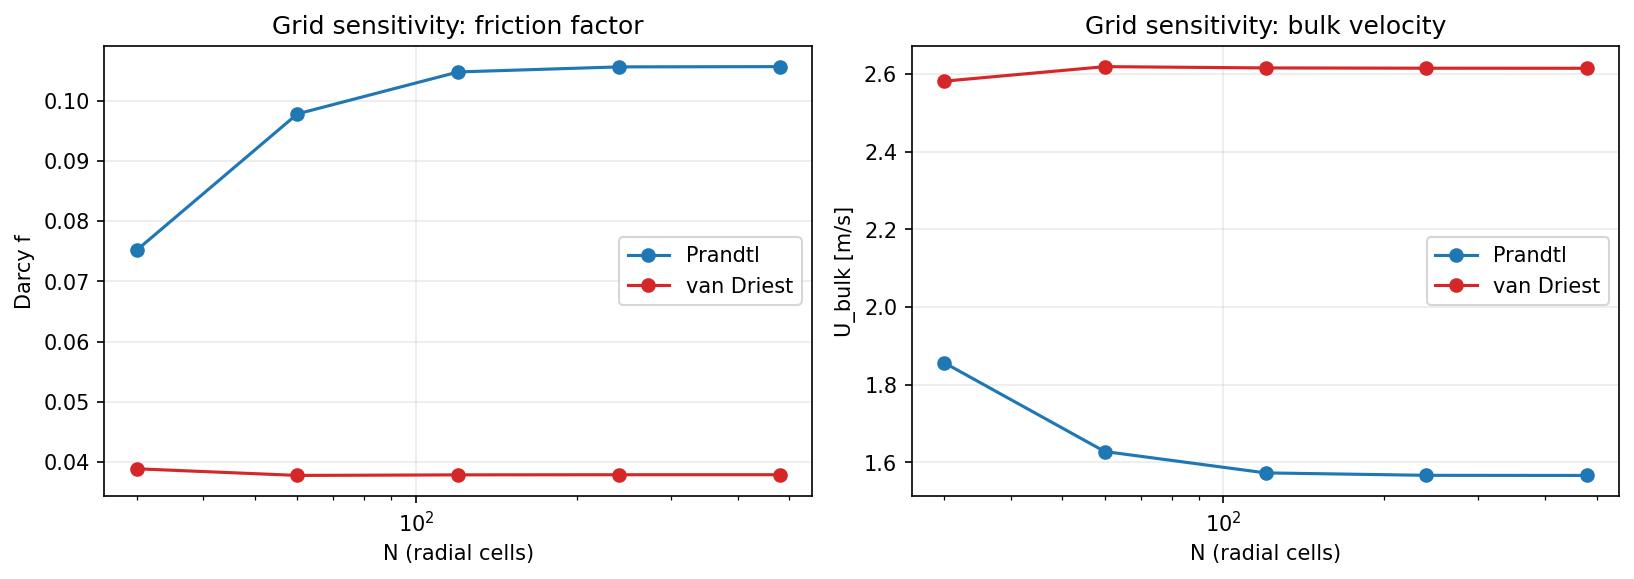

In [19]:
Ns = [30, 60, 120, 240, 480]
rows = []
for nm in ("Prandtl", "van Driest"):
    for n_ in Ns:
        rr_ = run_model(nm, n=n_)
        rows.append(dict(model=nm, N=n_, y1_plus=0.5 * rr_["h"] * U_TAU / NU, U_bulk=rr_["bulk"],
                         Re_D=rr_["Re"], Darcy_f=rr_["f"], iterations=rr_["iters"]))
grid_df = pd.DataFrame(rows)
for nm in ("Prandtl", "van Driest"):
    sel = grid_df.model == nm
    fine = grid_df[sel & (grid_df.N == 480)].Darcy_f.iloc[0]
    grid_df.loc[sel, "f rel. diff. vs N=480 [%]"] = 100 * (grid_df[sel].Darcy_f / fine - 1)
orders = {}
for nm in ("Prandtl", "van Driest"):
    f1, f2, f3 = [grid_df[(grid_df.model == nm) & (grid_df.N == n_)].Darcy_f.iloc[0] for n_ in (60, 120, 240)]
    orders[nm] = float(np.log2((f1 - f2) / (f2 - f3))) if (f1 - f2) * (f2 - f3) > 0 else float("nan")
display(grid_df)
print("Observed order of convergence of f (N = 60,120,240):", {k: round(v, 3) for k, v in orders.items()})

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
for nm, col in zip(("Prandtl", "van Driest"), ("C0", "C3")):
    s = grid_df[grid_df.model == nm]
    a.semilogx(s.N, s.Darcy_f, "o-", color=col, label=nm)
    b.semilogx(s.N, s.U_bulk, "o-", color=col, label=nm)
a.set(xlabel="N (radial cells)", ylabel="Darcy f", title="Grid sensitivity: friction factor"); a.legend()
b.set(xlabel="N (radial cells)", ylabel="U_bulk [m/s]", title="Grid sensitivity: bulk velocity"); b.legend()
fig.tight_layout(); show(fig, "fig10_grid_study")

,model,u_tau,Re_tau,y1_plus,U_bulk,Re_D,Darcy_f,f_Blasius,f_PK,iterations,dev_Blasius_%,dev_PK_%
0,Prandtl,0.06,100,0.416667,0.371936,1239.79,0.208188,0.0533212,0.0580497,57,290.442,258.637
1,van Driest,0.06,100,0.416667,0.654392,2181.31,0.0672538,0.0462975,0.0481005,62,45.2646,39.8194
2,Prandtl,0.08,133.333,0.555556,0.547216,1824.05,0.170983,0.0484147,0.0509698,57,253.163,235.459
3,van Driest,0.08,133.333,0.555556,0.954629,3182.1,0.0561825,0.0421268,0.0427522,63,33.3653,31.4143
4,Prandtl,0.1,166.667,0.694444,0.734715,2449.05,0.148201,0.0449766,0.0463641,56,229.507,219.646
5,van Driest,0.1,166.667,0.694444,1.26891,4229.71,0.0496851,0.0392337,0.0392644,63,26.6389,26.5398
6,Prandtl,0.12,200,0.833333,0.932174,3107.25,0.132574,0.0423782,0.0430637,55,212.835,207.856
7,van Driest,0.12,200,0.833333,1.59393,5313.11,0.0453432,0.0370595,0.0367554,64,22.3526,23.3647
8,Prandtl,0.15,250,1.04167,1.24416,4147.2,0.116284,0.0394274,0.0394925,54,194.932,194.446
9,van Driest,0.15,250,1.04167,2.09734,6991.13,0.0409199,0.0346019,0.0340291,65,18.2593,20.2499


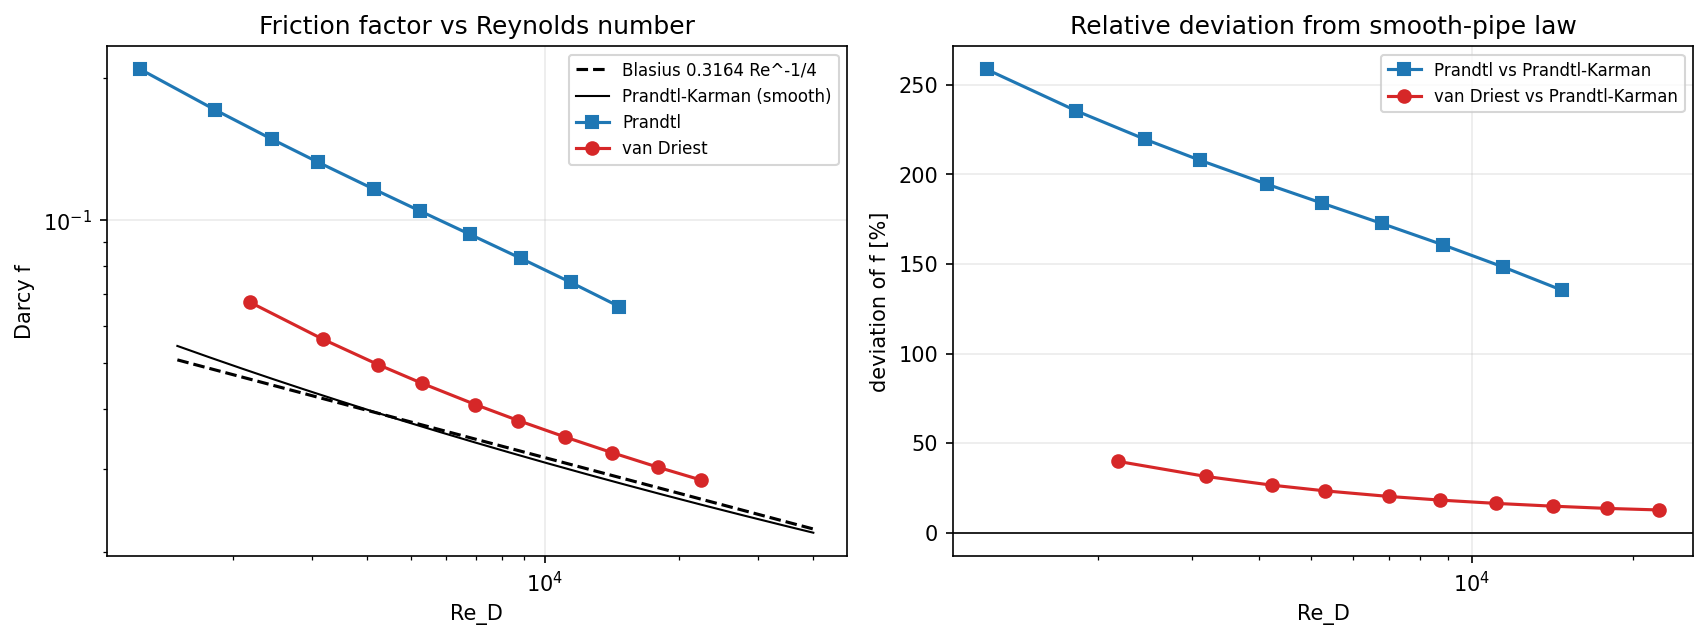

In [20]:
utaus = [0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.22, 0.27, 0.33, 0.40]
rows = []
for ut in utaus:
    for nm in ("Prandtl", "van Driest"):
        rr_ = run_model(nm, u_tau=ut)
        Re = rr_["Re"]
        rows.append(dict(model=nm, u_tau=ut, Re_tau=ut * R / NU, y1_plus=0.5 * rr_["h"] * ut / NU,
                         U_bulk=rr_["bulk"], Re_D=Re, Darcy_f=rr_["f"], f_Blasius=f_blasius(Re),
                         f_PK=f_prandtl_karman(Re), iterations=rr_["iters"]))
scan = pd.DataFrame(rows)
scan["dev_Blasius_%"] = 100 * (scan.Darcy_f / scan.f_Blasius - 1)
scan["dev_PK_%"] = 100 * (scan.Darcy_f / scan.f_PK - 1)
display(scan)

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.4))
reg = np.logspace(np.log10(1500), np.log10(4e4), 200)
a.loglog(reg, f_blasius(reg), "k--", label="Blasius 0.3164 Re^-1/4")
a.loglog(reg, [f_prandtl_karman(x) for x in reg], "k-", lw=1, label="Prandtl-Karman (smooth)")
for nm, col, mk in zip(("Prandtl", "van Driest"), ("C0", "C3"), ("s", "o")):
    s = scan[scan.model == nm]
    a.loglog(s.Re_D, s.Darcy_f, mk + "-", color=col, label=nm)
a.set(xlabel="Re_D", ylabel="Darcy f", title="Friction factor vs Reynolds number"); a.legend(fontsize=8)
for nm, col, mk in zip(("Prandtl", "van Driest"), ("C0", "C3"), ("s", "o")):
    s = scan[scan.model == nm]
    b.semilogx(s.Re_D, s["dev_PK_%"], mk + "-", color=col, label=nm + " vs Prandtl-Karman")
b.axhline(0, color="k", lw=0.8)
b.set(xlabel="Re_D", ylabel="deviation of f [%]", title="Relative deviation from smooth-pipe law"); b.legend(fontsize=8)
fig.tight_layout(); show(fig, "fig11_reynolds_scan")

In [21]:
results = {
    "params": dict(R=R, NU=NU, RHO=RHO, U_TAU=U_TAU, KAPPA=KAPPA, A_PLUS=A_PLUS, N=N, MAX_ITER=MAX_ITER, TOL=TOL,
                   h=h, source=source, Re_tau=U_TAU * R / NU, y1_plus=0.5 * h * U_TAU / NU),
    "laminar": dict(max_error=float(laminar_error), U_bulk=float(laminar_bulk),
                    U_bulk_exact=float(source * R**2 / (8 * NU)), Re_D=float(2 * R * laminar_bulk / NU)),
    "summary": {nm: {k: float(v) for k, v in summarise(base[nm]).items()} for nm in base},
    "original_script": {nm: dict(U_bulk=models[nm][1], Re_D=models[nm][2], f=models[nm][3],
                                 iters=int(models[nm][4]), resid=float(models[nm][5])) for nm in models},
    "verification": chk, "stress_check": stress_check, "contraction": rates, "orders": orders,
    "grid": grid_df.to_dict(orient="records"),
    "scan": scan.to_dict(orient="records"),
}
with open("results.json", "w") as fh:
    json.dump(results, fh, indent=1, default=float)
print("results.json written;", len(results), "top-level entries")

results.json written; 10 top-level entries
